### Weight and Bias steup

In [38]:
!pip install wandb -q

In [39]:
import wandb
print(wandb.run)

None


In [40]:
import wandb
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
wandb_key = user_secrets.get_secret("wandb")
print(type(wandb_key))

wandb.login(key=wandb_key)

<class 'str'>


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: taransaggu (taransaggu-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [41]:
run = wandb.init(
    entity="taransaggu-indian-institute-of-technology-madras",
    project="DL-GenAI-2026-T2",
    name="tfidf_logistic_baseline",
    config={
        "model": "TFIDF + Logistic Regression(Final)",
        "max_features": 20000,
        "max_iter": 500
    }
)

### Libraries Import

In [42]:
import pandas as pd
import numpy as np
import string
import seaborn as ns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

In [43]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

In [44]:
train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


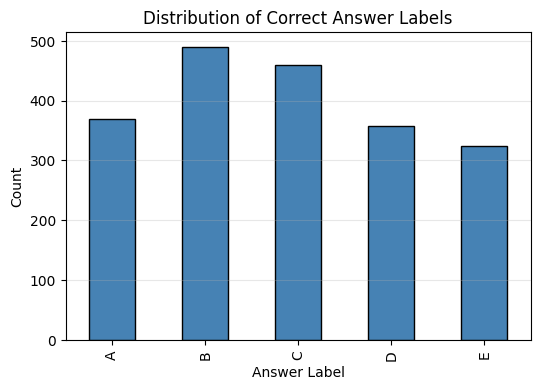

In [45]:
train["answer"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6,4),
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Correct Answer Labels")
plt.xlabel("Answer Label")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)

plt.show()

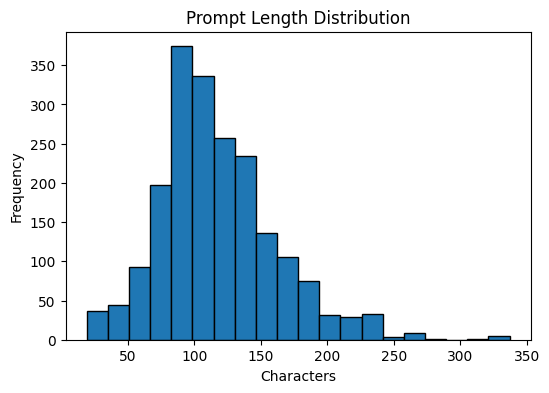

In [46]:
prompt_length = train["prompt"].str.len()

plt.figure(figsize=(6,4))

plt.hist(
    prompt_length,
    bins=20,
    edgecolor="black"
)

plt.title("Prompt Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

### Converts text to lowercase and removes punctuation

In [47]:
#cleaning
def clean(text):
    text = str(text).lower()

    for p in string.punctuation:
        text = text.replace(p, "")
        
    return text

In [48]:
#Cleaning of columns
cols = ["prompt", "A", "B", "C", "D", "E"]

for col in cols:
    train[col] = train[col].apply(clean)
    test[col] = test[col].apply(clean)

### Converting MCQ to Binary Classification Samples

In [49]:
labels = ["A","B","C","D","E"]

X = []
y = []
question_ids = []

In [50]:
print(len(X))

0


In [51]:
for i in range(len(train)):
    
    prompt = train.loc[i, "prompt"]
    answer = train.loc[i, "answer"]
    
    for label in labels:
        option = train.loc[i, label]
        #combining
        text = prompt + " [SEP] " + option
        X.append(text)
        
        y.append(1 if label == answer else 0)
        question_ids.append(i)

### Train,Validation Split

In [52]:
question_nums = list(range(len(train)))

train_q, val_q = train_test_split(
    question_nums,
    test_size=0.2,
    random_state=42
)

### Data Split

In [53]:
X_train = []
y_train = []

X_val = []
y_val = []


In [54]:
for idx, qid in enumerate(question_ids):
    
    if qid in train_q:
        X_train.append(X[idx])
        y_train.append(y[idx])
    else:
        X_val.append(X[idx])
        y_val.append(y[idx])

In [55]:
#Tf-IDF Vectorizer
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=20000,
    ngram_range=(1,2)
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

In [56]:
#Training logistic reg
lr = LogisticRegression(max_iter=500)
lr.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=500)

In [57]:
#predicting valid probability
valid_probs = lr.predict_proba(X_val_tfidf)[:, 1]

### Conerting back to MCQ Ranking

In [58]:
top1_predictions = []
top3_predictions = []
actual_labels = []

In [59]:
index = 0

for qid in val_q:
    
    scores = []
    
    for j in range(5):
        scores.append((labels[j], valid_probs[index]))
        index += 1
        
    scores.sort(key=lambda x: x[1], reverse=True)
    
    top1_predictions.append(scores[0][0])
    
    top3 = [
        scores[0][0],
        scores[1][0],
        scores[2][0]
    ]
    
    top3_predictions.append(top3)
    actual_labels.append(train.loc[qid, "answer"])

In [60]:
#MAP@3 function
def map_score(actual, preds):
    if actual in preds:
        rank = preds.index(actual) + 1
        return 1 / rank
    return 0

In [61]:
#accuracy
accuracy = accuracy_score(
    actual_labels,
    top1_predictions
)

In [62]:
#macro f1
macro_f1 = f1_score(
    actual_labels,
    top1_predictions,
    average="macro"
)

In [63]:
map_scores = []

for actual, pred in zip(actual_labels, top3_predictions):
    map_scores.append(map_score(actual, pred))

map3 = np.mean(map_scores)

In [64]:
print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("MAP@3:", map3)

Accuracy: 0.195
Macro F1: 0.1849163762358542
MAP@3: 0.34416666666666673


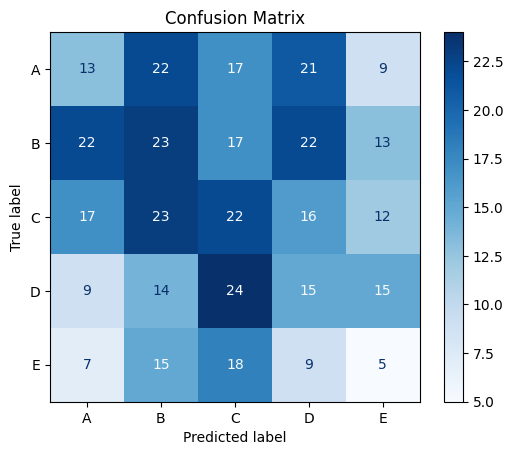

In [65]:

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    top1_predictions,
    actual_labels,
    display_labels=["A", "B", "C", "D", "E"],
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

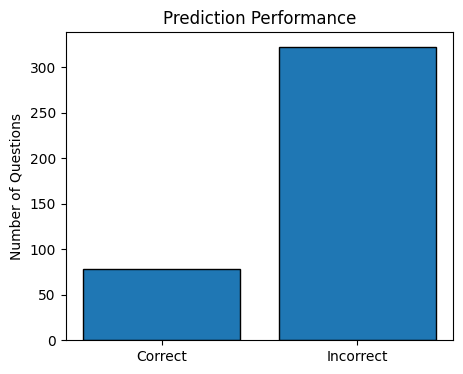

In [66]:
correct = sum(a == p for a, p in zip(actual_labels, top1_predictions))
incorrect = len(actual_labels) - correct

plt.figure(figsize=(5,4))

plt.bar(
    ["Correct","Incorrect"],
    [correct, incorrect],
    edgecolor="black"
)

plt.title("Prediction Performance")
plt.ylabel("Number of Questions")

plt.show()

In [67]:
#storing the run(wandb)
run.log({
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "map@3": map3
})

### Final training (FULL DATASET)

In [68]:
X_full = []
y_full = []

for i in range(len(train)):
    
    prompt = train.loc[i, "prompt"]
    answer = train.loc[i, "answer"]
    
    for label in labels:
        option = train.loc[i, label]
        
        text = prompt + " [SEP] " + option
        
        X_full.append(text)
        y_full.append(1 if label == answer else 0)

In [69]:
tfidf_final = TfidfVectorizer(
    stop_words="english",
    max_features=20000,
    ngram_range=(1,2)
)

X_full_tfidf = tfidf_final.fit_transform(X_full)

In [70]:
lr_final = LogisticRegression(max_iter=500)
lr_final.fit(X_full_tfidf, y_full)

LogisticRegression(max_iter=500)

In [71]:
X_test = []

for i in range(len(test)):
    
    prompt = test.loc[i, "prompt"]
    
    for label in labels:
        option = test.loc[i, label]
        text = prompt + " [SEP] " + option
        X_test.append(text)

In [72]:
X_test_tfidf = tfidf_final.transform(X_test)
test_probs = lr_final.predict_proba(X_test_tfidf)[:,1]

In [73]:
predictions = []
index = 0

for i in range(len(test)):
    
    scores = []
    
    for j in range(5):
        scores.append((labels[j], test_probs[index]))
        index += 1
    
    scores.sort(key=lambda x: x[1], reverse=True)
    
    pred = (
        scores[0][0] + " " +
        scores[1][0] + " " +
        scores[2][0]
    )
    
    predictions.append(pred)

### Submission

In [74]:
submission = pd.DataFrame({
    "ID": test["id"],
    "Prediction": predictions
})

In [75]:
submission.to_csv("submission.csv", index=False)

In [76]:
run.finish()

accuracy,▁
macro_f1,▁
map@3,▁
accuracy,0.195
macro_f1,0.18492
map@3,0.34417
